In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install pyinform

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 131.2/131.2 kB 1.0 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import fdrcorrection
import networkx as nx
from networkx.algorithms.community import (greedy_modularity_communities)
from tqdm.notebook import tqdm
from joblib import Parallel, delayed
from pyinform.transferentropy import transfer_entropy
from scipy import stats
import warnings

# **Data import**

In [ ]:
def load_spike_dataframe(file_path):
    return pd.read_csv(file_path,sep=',',header=0,
        names=['channel','time','amplitude','x','y','waveform'])

def build_binary_spike_matrix(spike_df, n_channels=4096):
    n_timepoints = int(spike_df['time'].max()) + 1
    spike_matrix = np.zeros((n_channels, n_timepoints),dtype=np.bool_)

    channel_idx = spike_df['channel'].to_numpy(dtype=int)
    time_idx = spike_df['time'].to_numpy(dtype=int)
    spike_matrix[channel_idx, time_idx] = True

    return spike_matrix

def rebin_spike_matrix(spike_matrix, fs_original=7062, fs_target=1000):
    n_channels, n_samples = spike_matrix.shape
    duration_s = n_samples / fs_original
    n_bins = int(np.floor(duration_s * fs_target))

    channel_idx, time_idx = np.where(spike_matrix)
    rebinned_time_idx = np.floor(time_idx * (fs_target / fs_original)).astype(int)

    valid_mask = rebinned_time_idx < n_bins
    rebinned_matrix = np.zeros((n_channels, n_bins),dtype=np.bool_)

    rebinned_matrix[
        channel_idx[valid_mask],
        rebinned_time_idx[valid_mask]] = True

    return rebinned_matrix

def remove_silent_channels(spike_matrix):
    active_mask = np.any(spike_matrix, axis=1)

    filtered_matrix = spike_matrix[active_mask]
    active_channel_ids = np.where(active_mask)[0]

    return filtered_matrix, active_channel_ids

In [ ]:
#CSV spikes path
file_path = '/content/df_spikes.csv'

In [ ]:
#Load spike dataframe
spike_df = load_spike_dataframe(file_path)
print(f'Spike dataframe shape: {spike_df.shape}')
print(f'Total spikes: {len(spike_df):}')

#Build binary spike matrix
binary_matrix_raw = build_binary_spike_matrix(spike_df,n_channels=4096)
print(f'Raw matrix shape: {binary_matrix_raw.shape}')
print(f'Raw spikes: {binary_matrix_raw.sum():}')

#Re-bin spike matrix
binary_matrix_binned = rebin_spike_matrix(binary_matrix_raw,fs_original=7062,fs_target=1000)
print(f'Binned matrix shape: {binary_matrix_binned.shape}')
print(f'Binned spikes: {binary_matrix_binned.sum():}') #Check consistency

#Remove silent channels
binary_matrix_filtered, active_channel_ids = (remove_silent_channels(binary_matrix_binned))
print(f'Active channels: {len(active_channel_ids)}')
print(f'Removed silent channels: ' f'{4096 - len(active_channel_ids)}')

Spike dataframe shape: (1824, 6)
Total spikes: 1824
Raw matrix shape: (4096, 4233929)
Raw spikes: 1,824
Binned matrix shape: (4096, 599536)
Binned spikes: 1,823
Active channels: 42
Removed silent channels: 4054


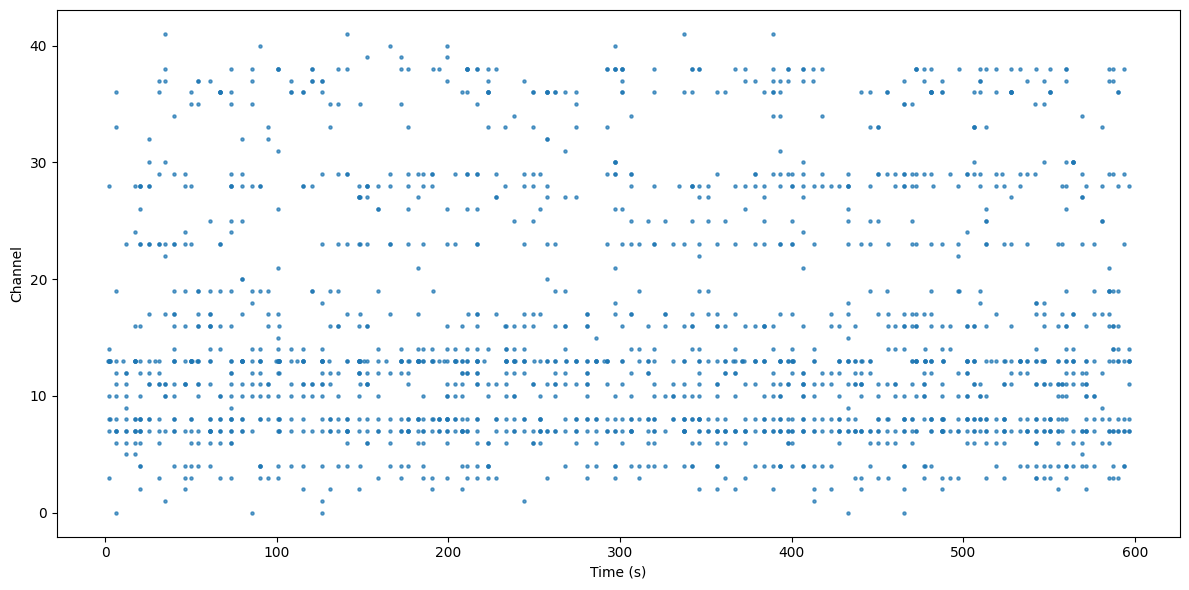

Active channels: 42
Mean firing rate: 3.04 Hz


In [ ]:
#Plot raster
channel_idx, time_idx = np.where(binary_matrix_filtered)
time_s = time_idx / 1000  #convert ms bins to seconds

plt.figure(figsize=(12, 6))
plt.scatter(time_s,channel_idx,s=5,alpha=0.7)
plt.xlabel('Time (s)')
plt.ylabel('Channel')
plt.tight_layout()
plt.show()

#Recording statistics
n_active_channels = binary_matrix_filtered.shape[0]
total_spikes = binary_matrix_filtered.sum()
recording_duration_s = (binary_matrix_filtered.shape[1] / 1000)
mean_firing_rate = (total_spikes / recording_duration_s)

print(f'Active channels: {n_active_channels}')
print(f'Mean firing rate: {mean_firing_rate:.2f} Hz')

# **Transfer Entropy**

In [ ]:
def compute_pair_te(source_idx,target_idx,spike_matrix,k=1,n_surrogates=300):
    source = spike_matrix[source_idx]
    target = spike_matrix[target_idx]

    real_te = transfer_entropy(source,target,k=k)
    T = len(source)

    rng = np.random.default_rng()
    surrogate_te = np.zeros(n_surrogates)
    random_shifts = rng.integers(1,T,size=n_surrogates)

    for s, shift in enumerate(random_shifts):
        shuffled_source = np.roll(source,shift)
        surrogate_te[s] = transfer_entropy(shuffled_source,target,k=k)

    p_value = (
        np.sum(surrogate_te >= real_te) + 1) / (n_surrogates + 1)

    return source_idx, target_idx, real_te, p_value

def compute_transfer_entropy_network(spike_matrix,k=1, n_surrogates=300,alpha=0.05):

    n_channels = spike_matrix.shape[0]
    te_matrix = np.zeros((n_channels, n_channels))
    p_matrix = np.ones((n_channels, n_channels))

    channel_pairs = [
        (i, j)
        for i in range(n_channels)
        for j in range(n_channels)
        if i != j]

    results = Parallel(
        n_jobs=-1,
        backend='loky'
    )(
        delayed(compute_pair_te)(
            i,j,spike_matrix,k,n_surrogates)
        for i, j in tqdm(
            channel_pairs,desc=f'Computing TE (k={k})'))

    for i, j, te, p in results:
        te_matrix[i, j] = te
        p_matrix[i, j] = p

    #Naive threshold
    te_naive = te_matrix.copy()
    te_naive[p_matrix > alpha] = 0

    #FDR correction
    off_diag = np.where(~np.eye(n_channels, dtype=bool))
    p_values_flat = p_matrix[off_diag]

    significant_fdr, p_values_corrected = (
        fdrcorrection(p_values_flat,alpha=alpha,method='indep'))

    fdr_mask = np.zeros_like(p_matrix,dtype=bool)
    fdr_mask[off_diag] = significant_fdr
    te_fdr = te_matrix.copy()
    te_fdr[~fdr_mask] = 0

    return (te_matrix,te_naive,te_fdr,p_matrix)

In [ ]:
#Compute transfer entropy network
TE_raw, TE_naive, TE_fdr, p_vals = (
    compute_transfer_entropy_network(binary_matrix_filtered,k=1,n_surrogates=300,alpha=0.05))

#Network statistics
n_nodes = TE_fdr.shape[0]
n_possible_edges = (n_nodes * (n_nodes - 1))
n_significant_edges = np.count_nonzero(TE_fdr)

network_density = (n_significant_edges / n_possible_edges)
mean_te = TE_fdr[TE_fdr > 0].mean()

print(f'Significant edges: {n_significant_edges}')
print(f'Network density: {network_density:.4f}')
print(f'Mean TE: {mean_te:.6f}')

#Build directed graph
G = nx.from_numpy_array(TE_fdr,create_using=nx.DiGraph)

print(
    f'Graph | '
    f'Nodes: {G.number_of_nodes()} | '
    f'Edges: {G.number_of_edges()}')

Computing TE (k=1):   0%|          | 0/1722 [00:00<?, ?it/s]

Significant edges: 288
Network density: 0.1672
Mean TE: 0.000045
Graph | Nodes: 42 | Edges: 288


# **Graph**

In [ ]:
def calculate_network_metrics(G,n_null_networks=2000):
    #Largest strongly connected component
    largest_scc = max(nx.strongly_connected_components(G),key=len)
    G_scc = G.subgraph(largest_scc).copy()
    real_metrics = {}

    #Real network metrics
    real_metrics['avg_shortest_path'] = (nx.average_shortest_path_length(G_scc))
    real_metrics['avg_degree'] = np.mean([degree for _, degree in G.degree()])
    real_metrics['avg_clustering'] = np.mean(list(nx.clustering(G).values()))
    communities = greedy_modularity_communities(G.to_undirected())
    real_metrics['modularity'] = (nx.community.modularity(G, communities))
    eigenvector = nx.eigenvector_centrality(G, max_iter=1000)
    real_metrics['avg_eigenvector'] = np.mean(list(eigenvector.values()))

    #Null models
    null_metrics = {metric: [] for metric in real_metrics}
    in_degree_sequence = [G.in_degree(node) for node in G.nodes()]
    out_degree_sequence = [G.out_degree(node) for node in G.nodes()]

    for _ in tqdm(
        range(n_null_networks),
        desc='Generating null networks',
        leave=False):

        G_rand = nx.directed_configuration_model(
            in_degree_sequence,out_degree_sequence)
        G_rand = nx.DiGraph(G_rand)
        G_rand.remove_edges_from(nx.selfloop_edges(G_rand))

        rand_scc = max(nx.strongly_connected_components(G_rand),key=len)
        G_rand_scc = G_rand.subgraph(rand_scc).copy()


        null_metrics['avg_shortest_path'].append(nx.average_shortest_path_length(G_rand_scc ))

        null_metrics['avg_degree'].append(
            np.mean([degree for _, degree in G_rand.degree()]))

        null_metrics['avg_clustering'].append(
            np.mean(list(nx.clustering(G_rand).values())))

        rand_communities = (greedy_modularity_communities(
                G_rand.to_undirected()))

        null_metrics['modularity'].append(
            nx.community.modularity(G_rand,rand_communities))

        rand_eigenvector = (
            nx.eigenvector_centrality(G_rand,max_iter=1000))

        null_metrics['avg_eigenvector'].append(
            np.mean(list(rand_eigenvector.values())))

    #Z-scores
    z_scores = {}

    for metric in real_metrics:
        mean_null = np.mean(null_metrics[metric])
        std_null = np.std(null_metrics[metric])

        z_scores[metric] = (
            real_metrics[metric] - mean_null) / std_null

    return real_metrics, z_scores

In [ ]:
#Compute network topology metrics
real_metrics, z_scores = (
    calculate_network_metrics(G,n_null_networks=2000))

print(
    f'{'Metric':<25}'
    f'{'Real':<15}'
    f'{'Z-score':<15}')

for metric in real_metrics:
    print(
        f'{metric:<25}'
        f'{real_metrics[metric]:<15.4f}'
        f'{z_scores[metric]:<15.4f}')

Generating null networks:   0%|          | 0/2000 [00:00<?, ?it/s]

Metric                   Real           Z-score        
avg_shortest_path        2.0508         -2.9921        
avg_degree               13.7143        9.8733         
avg_clustering           0.3831         7.0614         
modularity               0.1760         0.9609         
avg_eigenvector          0.1208         -4.6434        
